# Customer Churn Prediction: 

# **Random Forest vs XGBoost**

## 1. Imports

In [15]:
pip install imbalanced-learn xgboost

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [16]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report)
from imblearn.pipeline import Pipeline            
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Load and inspect the data

In [17]:
df = pd.read_csv("Telco-Customer-Churn.csv")


In [18]:
df.shape


(7043, 21)

In [19]:
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [20]:
df.tail()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [22]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 3. Clean the data

In [23]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"].isnull().sum()
display(df.loc[df["TotalCharges"].isnull(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]])

,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [24]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")

df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Missing values left:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values left: 0
Duplicate rows: 22


## 4. Explore: how imbalanced is the target?

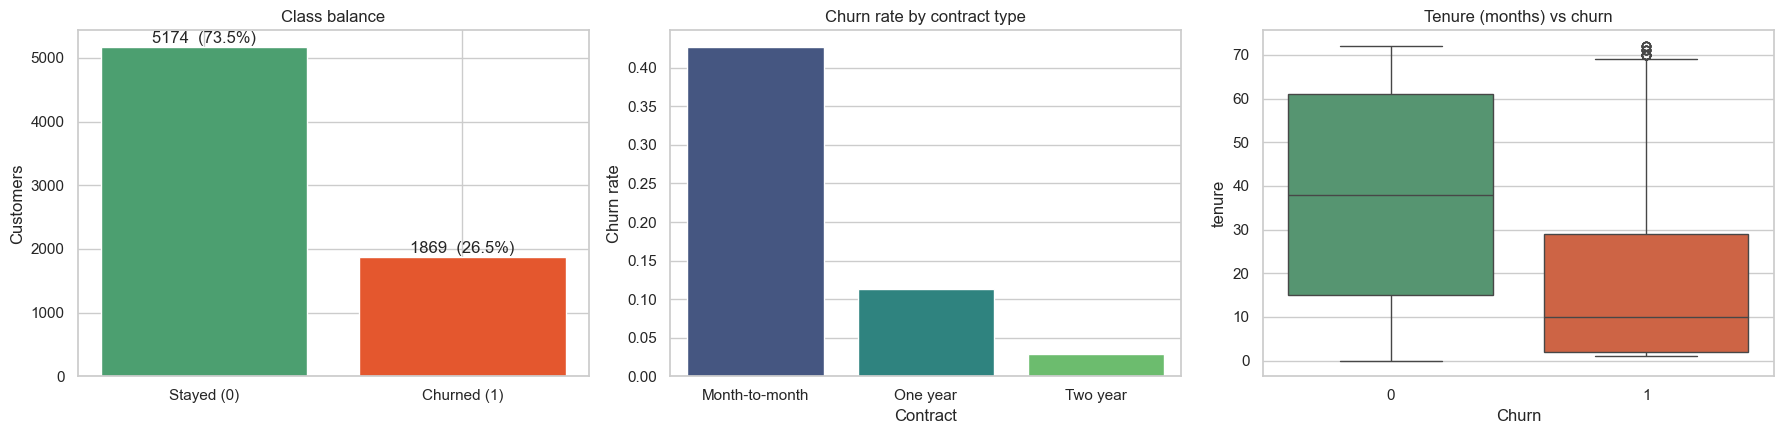

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

counts = df["Churn"].value_counts().sort_index()
axes[0].bar(["Stayed (0)", "Churned (1)"], counts.values, color=["#4C9F70", "#E4572E"])
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 60, f"{v}  ({v / len(df):.1%})", ha="center")
axes[0].set_title("Class balance")
axes[0].set_ylabel("Customers")

sns.barplot(data=df, x="Contract", y="Churn", ax=axes[1], palette="viridis", errorbar=None)
axes[1].set_title("Churn rate by contract type")
axes[1].set_ylabel("Churn rate")

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[2], palette=["#4C9F70", "#E4572E"])
axes[2].set_title("Tenure (months) vs churn")

plt.tight_layout()
plt.show()

## 5. Testing/Training Data Splitting

In [26]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Churn rate  train: {:.3f}   test: {:.3f}".format(y_train.mean(), y_test.mean()))

Train: (5634, 19)  Test: (1409, 19)
Churn rate  train: 0.265   test: 0.265


## 6. Preprocessing: OneHotEncoder + StandardScaler

In [27]:
cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()
print("Categorical:", cat_cols)
print("Numeric:", num_cols)

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']


## 7. Balance the classes by using SMOTE

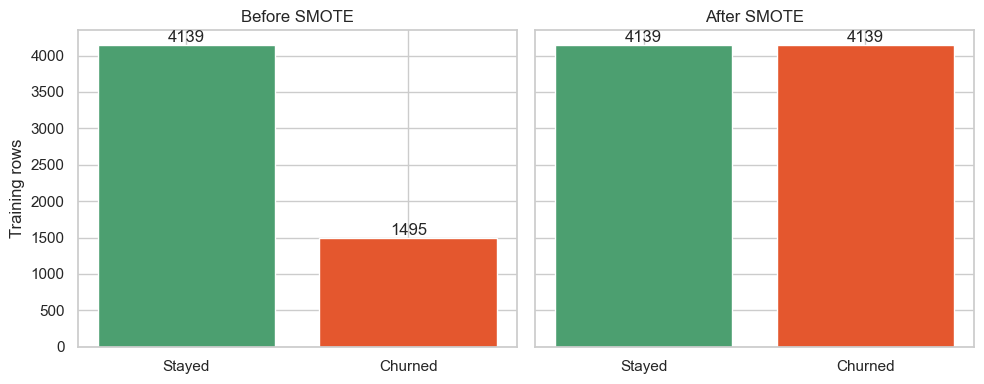

In [28]:
X_train_enc = preprocessor.fit_transform(X_train)
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_enc, y_train)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, labels, title in zip(axes, [y_train, y_res], ["Before SMOTE", "After SMOTE"]):
    c = pd.Series(labels).value_counts().sort_index()
    ax.bar(["Stayed", "Churned"], c.values, color=["#4C9F70", "#E4572E"])
    for i, v in enumerate(c.values):
        ax.text(i, v + 40, str(v), ha="center")
    ax.set_title(title)
axes[0].set_ylabel("Training rows")
plt.tight_layout()
plt.show()

## 8. Build the two model pipelines

In [29]:
def make_pipeline(model):
    return Pipeline([
        ("prep", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", model),
    ])

rf_pipe = make_pipeline(RandomForestClassifier(
    n_estimators=300, max_depth=12, min_samples_leaf=3,
    n_jobs=-1, random_state=RANDOM_STATE))

xgb_pipe = make_pipeline(XGBClassifier(
    n_estimators=300, learning_rate=0.05, max_depth=4,
    subsample=0.8, colsample_bytree=0.8,
    eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=-1))

pipelines = {"Random Forest": rf_pipe, "XGBoost": xgb_pipe}

## 9. Cross-validation

In [30]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_results = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_results[name] = scores
    print(f"{name:14s} CV ROC-AUC: {scores.mean():.4f} (+/- {scores.std():.4f})   folds: {np.round(scores, 3)}")

Random Forest  CV ROC-AUC: 0.8410 (+/- 0.0085)   folds: [0.834 0.83  0.841 0.846 0.854]
XGBoost        CV ROC-AUC: 0.8426 (+/- 0.0097)   folds: [0.835 0.83  0.841 0.856 0.85 ]


## 10. Training and Testing the Model.

In [31]:
rows, proba, preds = [], {}, {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    p = pipe.predict_proba(X_test)[:, 1]
    yhat = pipe.predict(X_test)
    proba[name], preds[name] = p, yhat
    rows.append({
        "Model": name,
        "CV ROC-AUC": cv_results[name].mean(),
        "Test ROC-AUC": roc_auc_score(y_test, p),
        "Accuracy": accuracy_score(y_test, yhat),
        "Precision": precision_score(y_test, yhat),
        "Recall": recall_score(y_test, yhat),
        "F1": f1_score(y_test, yhat),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
display(results)

for name in pipelines:
    print(f"===== {name} =====")
    print(classification_report(y_test, preds[name], target_names=["Stayed", "Churned"]))

,CV ROC-AUC,Test ROC-AUC,Accuracy,Precision,Recall,F1
Model,,,,,,
Random Forest,0.8410,0.8362,0.7644,0.5463,0.6631,0.599
XGBoost,0.8426,0.8394,0.7814,0.5833,0.6176,0.600


===== Random Forest =====
              precision    recall  f1-score   support

      Stayed       0.87      0.80      0.83      1035
     Churned       0.55      0.66      0.60       374

    accuracy                           0.76      1409
   macro avg       0.71      0.73      0.72      1409
weighted avg       0.78      0.76      0.77      1409

===== XGBoost =====
              precision    recall  f1-score   support

      Stayed       0.86      0.84      0.85      1035
     Churned       0.58      0.62      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.79      0.78      0.78      1409



## 11. ROC curves

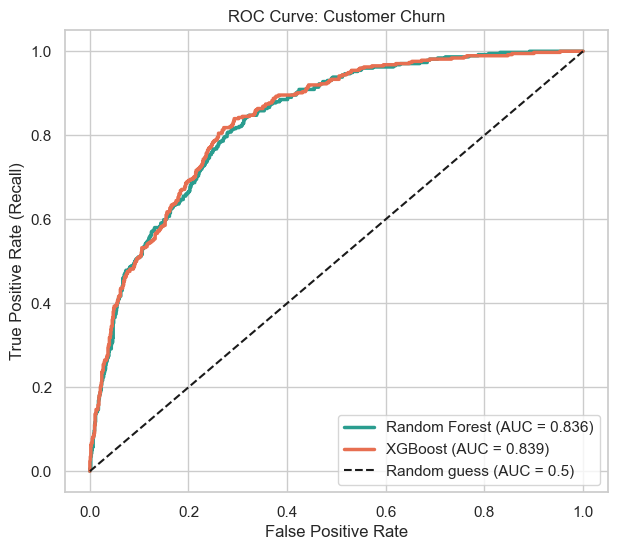

Target ROC-AUC > 0.80 reached?
  Random Forest  0.8362  -> YES
  XGBoost        0.8394  -> YES


In [32]:
plt.figure(figsize=(7, 6))
colors = {"Random Forest": "#2A9D8F", "XGBoost": "#E76F51"}
for name, p in proba.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2.5, color=colors[name], label=f"{name} (AUC = {roc_auc_score(y_test, p):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve: Customer Churn")
plt.legend(loc="lower right")
plt.show()

print("Target ROC-AUC > 0.80 reached?")
for name, p in proba.items():
    print(f"  {name:14s} {roc_auc_score(y_test, p):.4f}  ->", "YES" if roc_auc_score(y_test, p) > 0.80 else "NO")

## 12. Confusion matrices

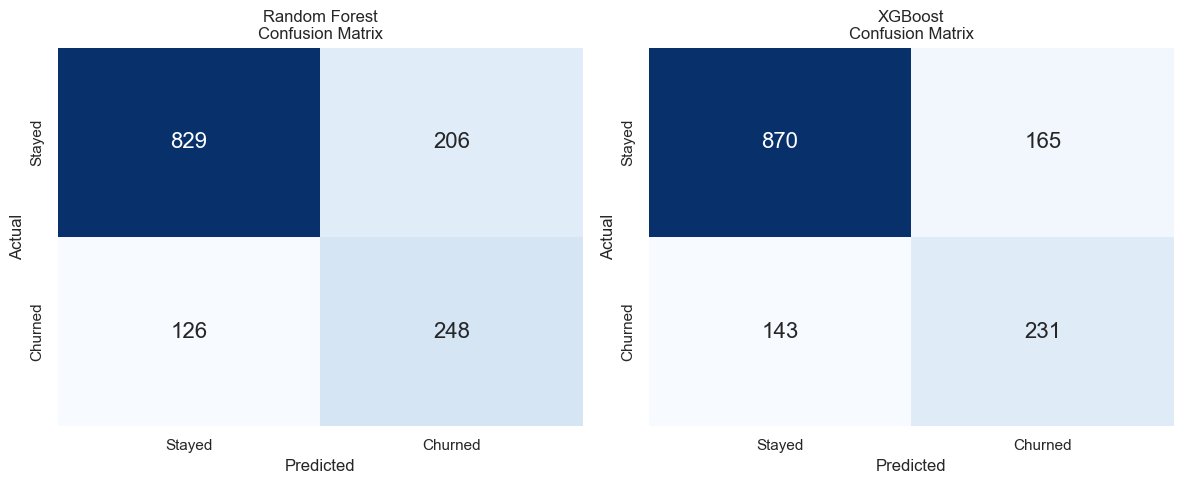

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, yhat) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, yhat)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Stayed", "Churned"], yticklabels=["Stayed", "Churned"],
                annot_kws={"size": 16})
    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 13. Top 10 most important features

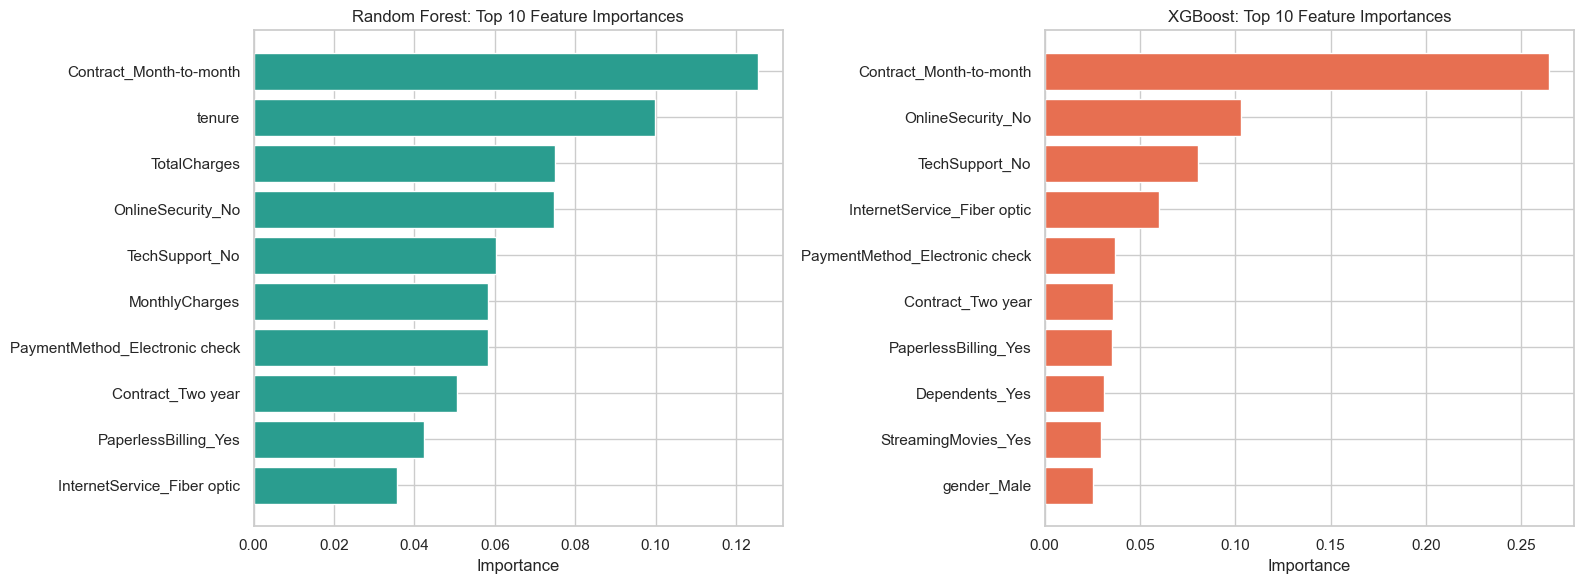

Top 10 features: Random Forest


,importance
Contract_Month-to-month,0.1254
tenure,0.0998
TotalCharges,0.0750
OnlineSecurity_No,0.0746
TechSupport_No,0.0604
MonthlyCharges,0.0583
PaymentMethod_Electronic check,0.0583
Contract_Two year,0.0505
PaperlessBilling_Yes,0.0425
InternetService_Fiber optic,0.0356


Top 10 features: XGBoost


,importance
Contract_Month-to-month,0.2645
OnlineSecurity_No,0.1031
TechSupport_No,0.0807
InternetService_Fiber optic,0.0599
PaymentMethod_Electronic check,0.0368
Contract_Two year,0.0360
PaperlessBilling_Yes,0.0354
Dependents_Yes,0.0310
StreamingMovies_Yes,0.0299
gender_Male,0.0256


In [34]:
feature_names = (rf_pipe.named_steps["prep"].get_feature_names_out())
feature_names = [n.replace("cat__", "").replace("num__", "") for n in feature_names]

importances = {
    "Random Forest": rf_pipe.named_steps["model"].feature_importances_,
    "XGBoost": xgb_pipe.named_steps["model"].feature_importances_,
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (name, imp) in zip(axes, importances.items()):
    top = pd.Series(imp, index=feature_names).sort_values(ascending=False).head(10)[::-1]
    ax.barh(top.index, top.values, color=colors[name])
    ax.set_title(f"{name}: Top 10 Feature Importances")
    ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

for name, imp in importances.items():
    print(f"Top 10 features: {name}")
    display(pd.Series(imp, index=feature_names).sort_values(ascending=False).head(10)
            .round(4).rename("importance").to_frame())

## 14. Saving the trained models

In [35]:
joblib.dump(rf_pipe, "rf_churn_model.joblib")
joblib.dump(xgb_pipe, "xgb_churn_model.joblib")
print("Saved: rf_churn_model.joblib, xgb_churn_model.joblib")

Saved: rf_churn_model.joblib, xgb_churn_model.joblib
